# 위고비 보험사 종합영향: 연령·성별 포트폴리오 분석

국내 판매 가능 연령 19~74세와 남녀 구성을 반영해 약제비 특약 NPV와 기존 보험금 조정액을 결합한다. 기존 62세·남성 72%·여성 28% 결과는 **SELECT 유사 대표집단 참고분석**으로만 보존한다.

## 1. 계산 범위와 입력

- 주결과: 국내 일반인구 구성 대리 × 기준 담보 보유율, 최초 계약 1,000건
- 판매가격: `sale_product_age_lookup.csv`의 연령·성별·상품별 목표이익률 10% 확정 보험료
- 보험기간: 19~69세 10년, 70~74세 5년
- 기존 보험금: 특약 없음 `A`와 특약 있음 `A+B`의 차이만 반영

시장은 저확산→고확산 효과를 최종 손익에 더하지 않는다.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

def find_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / 'config' / 'insurer_total_impact.json').exists():
            return candidate
    raise FileNotFoundError('저장소 루트를 찾을 수 없습니다.')

ROOT = find_root()
OUT = ROOT / 'outputs' / 'insurer_total_impact'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
required = [
    'portfolio_composition.csv', 'portfolio_rider_summary.csv',
    'portfolio_total_impact.csv', 'select_reference_vs_portfolio.csv',
    'portfolio_existing_claims_components.csv', 'validation.json'
]
missing = [name for name in required if not (OUT / name).exists()]
if missing:
    raise FileNotFoundError(f'결과 파일이 없습니다: {missing}. 저장소 루트에서 python -m models.impact.insurer_total_impact 를 실행하세요.')

font_candidates = ['AppleGothic', 'NanumGothic', 'Malgun Gothic', 'Noto Sans CJK KR']
available = {f.name for f in font_manager.fontManager.ttflist}
font_name = next((name for name in font_candidates if name in available), 'DejaVu Sans')
plt.rcParams.update({'font.family': font_name, 'axes.unicode_minus': False, 'figure.dpi': 120})

composition = pd.read_csv(OUT / 'portfolio_composition.csv')
rider = pd.read_csv(OUT / 'portfolio_rider_summary.csv')
total = pd.read_csv(OUT / 'portfolio_total_impact.csv')
comparison = pd.read_csv(OUT / 'select_reference_vs_portfolio.csv')
components = pd.read_csv(OUT / 'portfolio_existing_claims_components.csv')
validation = json.loads((OUT / 'validation.json').read_text(encoding='utf-8'))
print(f'저장소: {ROOT}')
print(f'한글 글꼴: {font_name}')
print(f'포트폴리오 구성 {len(composition):,}행 · 종합영향 {len(total):,}행 · 검증 {validation["status"]}')

저장소: /Users/dapanman/Desktop/glp1_pricing_analysis
한글 글꼴: AppleGothic
포트폴리오 구성 336행 · 종합영향 72행 · 검증 PASS


## 2. 국내 일반인구 구성 대리의 연령대·성별 구성

KOSIS 2025년 12월 전국 주민등록인구를 사용한다. 적격률과 비당뇨 비율은 연령·성별 세분자료가 없어 모든 셀에 같은 국민건강영양조사 전체 성인 비율을 적용했으며, 공통비율은 정규화된 구성비에 영향을 주지 않는다. 따라서 기준 시나리오의 표시명은 `국내 일반인구 구성 대리`다.

성별,남,여
가입연령대,,
19~29세,8.04,7.45
30~39세,8.82,8.04
40~49세,9.75,9.40
50~59세,11.00,10.81
60~69세,9.87,10.14
70~74세,3.14,3.53


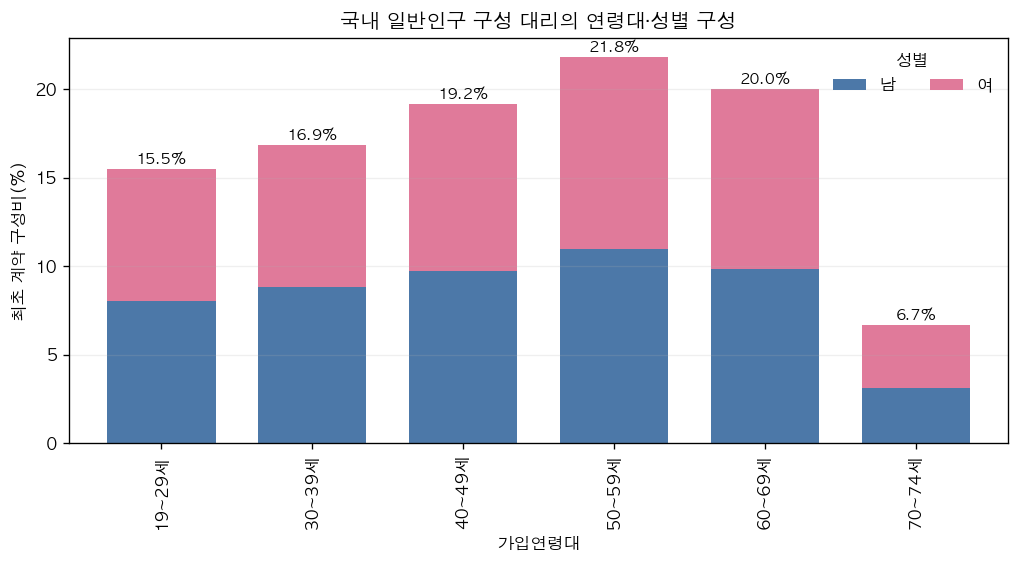

In [2]:
base_comp = composition.loc[composition['enrollment_scenario_id'].eq('base')].copy()
base_comp['연령대'] = pd.cut(base_comp['issue_age'], [18, 29, 39, 49, 59, 69, 74], labels=['19~29세','30~39세','40~49세','50~59세','60~69세','70~74세'])
mix = base_comp.pivot_table(index='연령대', columns='sex', values='portfolio_weight', aggfunc='sum', observed=True).reindex(columns=['남','여']) * 100
display(mix.round(2).rename_axis(index='가입연령대', columns='성별'))
fig, ax = plt.subplots(figsize=(8.6, 4.8))
mix.plot(kind='bar', stacked=True, color=['#4C78A8','#E07A9A'], ax=ax, width=0.72)
for i, value in enumerate(mix.sum(axis=1)):
    ax.text(i, value + 0.25, f'{value:.1f}%', ha='center', fontsize=9)
ax.set(title='국내 일반인구 구성 대리의 연령대·성별 구성', xlabel='가입연령대', ylabel='최초 계약 구성비(%)')
ax.legend(title='성별', frameon=False, ncol=2)
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(FIG / 'portfolio_01_age_sex_mix.png', dpi=300, facecolor='white', bbox_inches='tight')
plt.show()

## 3. 상품별 특약 NPV·기존 보험금 조정·종합영향

국내 일반인구 구성 대리와 기준 담보 보유율에서 8개 상품을 비교한다. 기존 보험금 조정액은 조건부 SELECT 유사 고위험군 비중과 담보 보유율을 적용하므로 특약 NPV보다 훨씬 작아 별도 패널에 표시한다.

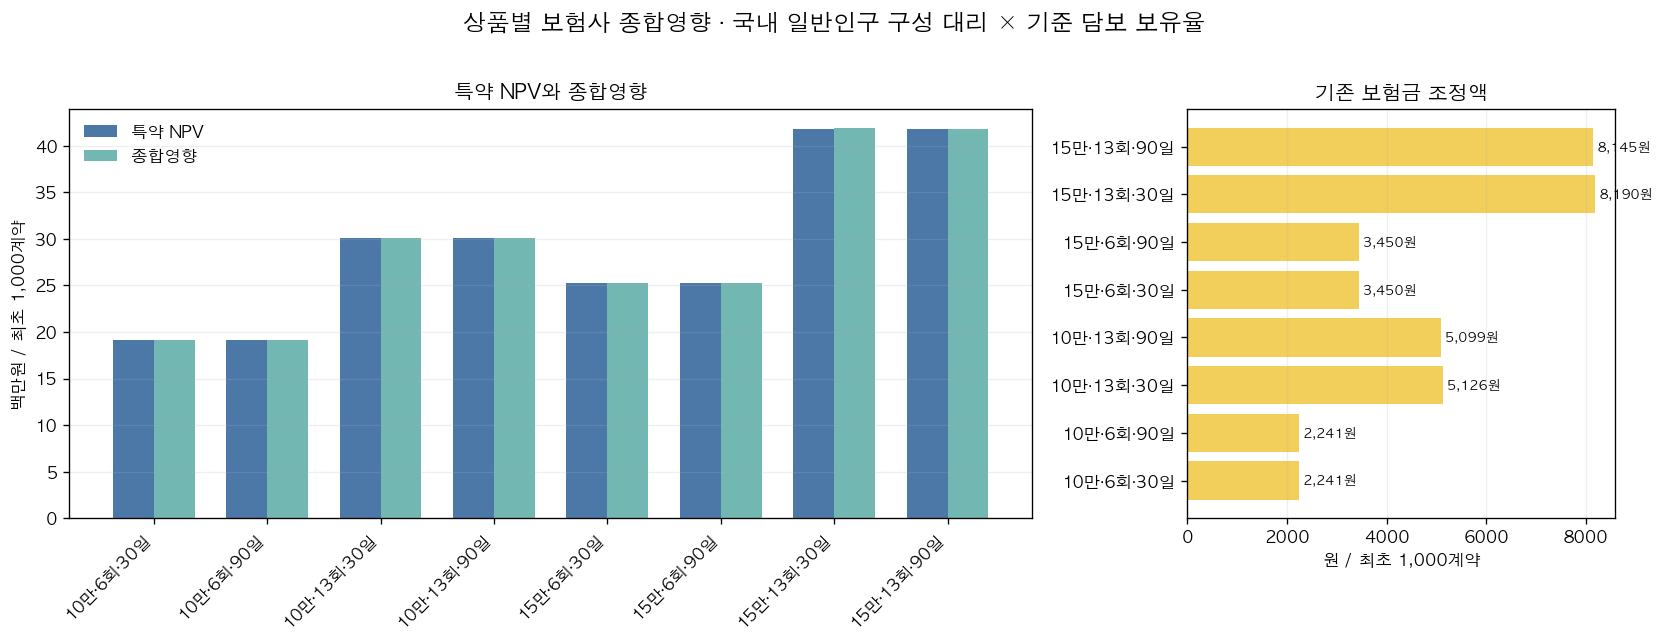

In [3]:
product = total.loc[total['enrollment_scenario_id'].eq('base') & total['coverage_scenario_id'].eq('base')].copy()
product['상품'] = product.apply(lambda r: f"{int(r['benefit_per_dispense_krw']/10000)}만·{int(r['max_claims'])}회·{int(r['waiting_days'])}일", axis=1)
product = product.sort_values(['benefit_per_dispense_krw','max_claims','waiting_days'])
x = np.arange(len(product))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios':[2.25,1]})
axes[0].bar(x - .18, product['rider_npv_krw']/1e6, width=.36, label='특약 NPV', color='#4C78A8')
axes[0].bar(x + .18, product['insurer_total_impact_krw']/1e6, width=.36, label='종합영향', color='#72B7B2')
axes[0].set_xticks(x, product['상품'], rotation=45, ha='right')
axes[0].set_ylabel('백만원 / 최초 1,000계약')
axes[0].set_title('특약 NPV와 종합영향')
axes[0].legend(frameon=False)
axes[0].grid(axis='y', alpha=.2)
axes[1].barh(product['상품'], product['existing_claims_adjustment_krw'], color='#F2CF5B')
for i, v in enumerate(product['existing_claims_adjustment_krw']):
    axes[1].text(v, i, f' {v:,.0f}원', va='center', fontsize=8)
axes[1].set_title('기존 보험금 조정액')
axes[1].set_xlabel('원 / 최초 1,000계약')
axes[1].grid(axis='x', alpha=.2)
fig.suptitle('상품별 보험사 종합영향 · 국내 일반인구 구성 대리 × 기준 담보 보유율', y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIG / 'portfolio_02_product_total_impact.png', dpi=300, facecolor='white', bbox_inches='tight')
plt.show()

## 4. 가입구성 시나리오별 종합영향

대표 상품(10만 원·13회·90일)과 기준 담보 보유율에서 국내 일반인구 구성 대리·젊은층 집중·고령층 집중을 비교한다. 각 구성은 합계가 1이 되도록 다시 정규화했다.

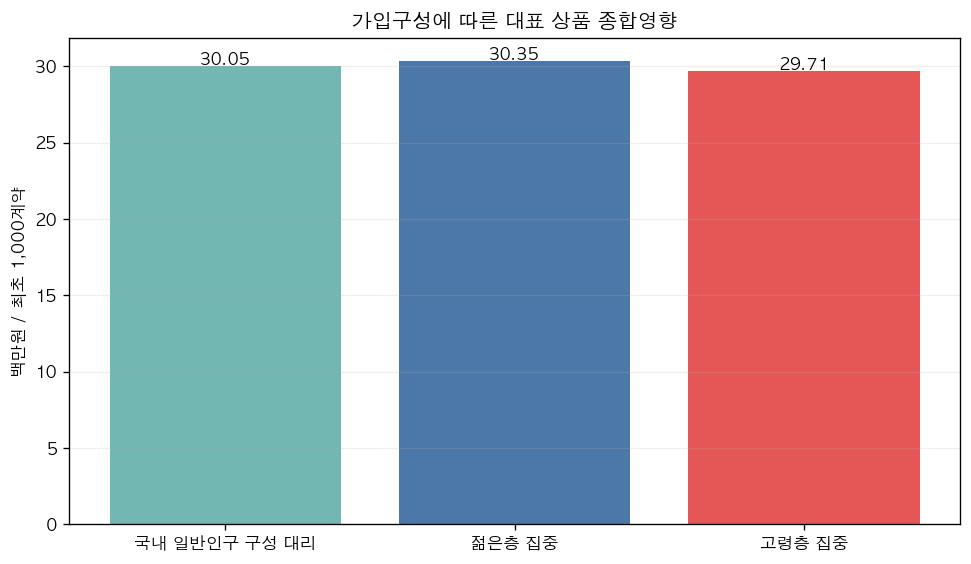

,enrollment_scenario_id,weighted_average_monthly_premium_krw,rider_npv_krw,existing_claims_adjustment_krw,insurer_total_impact_krw
0,base,3151.27,30043629.80,5099.23,30048729.03
1,younger_focus,3148.08,30344115.86,4497.87,30348613.73
2,older_high_risk_focus,3154.88,29703373.53,5780.18,29709153.71


In [4]:
scenario_order = ['base','younger_focus','older_high_risk_focus']
scenario_names = {'base':'국내 일반인구 구성 대리','younger_focus':'젊은층 집중','older_high_risk_focus':'고령층 집중'}
scenario = total.loc[total['product_id'].eq('benefit100k_max13_wait90') & total['coverage_scenario_id'].eq('base')].set_index('enrollment_scenario_id').loc[scenario_order].reset_index()
fig, ax = plt.subplots(figsize=(8.2, 4.8))
bars = ax.bar([scenario_names[x] for x in scenario['enrollment_scenario_id']], scenario['insurer_total_impact_krw']/1e6, color=['#72B7B2','#4C78A8','#E45756'])
for bar, value in zip(bars, scenario['insurer_total_impact_krw']/1e6):
    ax.text(bar.get_x()+bar.get_width()/2, value+.08, f'{value:.2f}', ha='center', fontweight='bold')
ax.set(title='가입구성에 따른 대표 상품 종합영향', ylabel='백만원 / 최초 1,000계약')
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(FIG / 'portfolio_03_enrollment_scenarios.png', dpi=300, facecolor='white', bbox_inches='tight')
plt.show()
display(scenario[['enrollment_scenario_id','weighted_average_monthly_premium_krw','rider_npv_krw','existing_claims_adjustment_krw','insurer_total_impact_krw']].round(2))

## 5. SELECT 62세 참고분석과 포트폴리오 주결과

기존 결과는 삭제하지 않고 참고분석으로 둔다. 포트폴리오 주결과는 연령·성별 보험료와 보험기간을 셀별로 적용하며, 기존 보험금 조정은 전체 가입자가 아니라 SELECT 유사 고위험군 비중에만 적용한다.

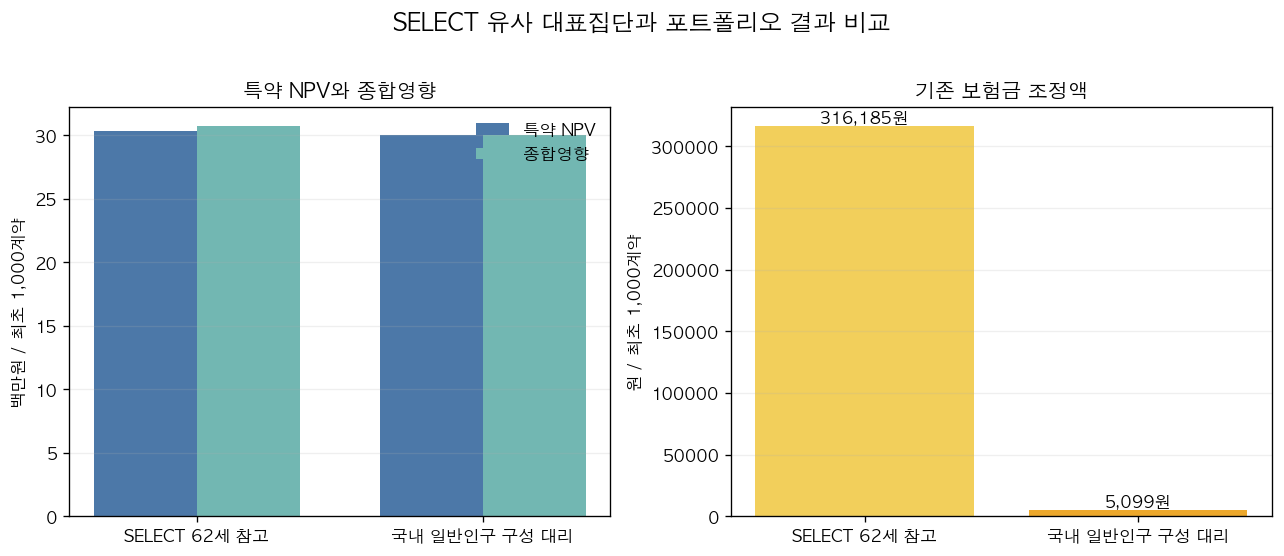

,구분,rider_npv_krw,existing_claims_adjustment_krw,insurer_total_impact_krw
0,SELECT 62세 참고,30387622.83,316184.96,30703807.79
1,국내 일반인구 구성 대리,30043629.80,5099.23,30048729.03


In [5]:
compare = comparison.loc[(comparison['analysis_group'].eq('select_reference')) | ((comparison['analysis_group'].eq('portfolio')) & comparison['enrollment_scenario_id'].eq('base'))].copy()
compare['구분'] = ['SELECT 62세 참고' if x == 'select_reference' else '국내 일반인구 구성 대리' for x in compare['analysis_group']]
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.5))
x = np.arange(len(compare))
axes[0].bar(x-.18, compare['rider_npv_krw']/1e6, .36, label='특약 NPV', color='#4C78A8')
axes[0].bar(x+.18, compare['insurer_total_impact_krw']/1e6, .36, label='종합영향', color='#72B7B2')
axes[0].set_xticks(x, compare['구분'])
axes[0].set_ylabel('백만원 / 최초 1,000계약')
axes[0].legend(frameon=False)
axes[0].set_title('특약 NPV와 종합영향')
axes[1].bar(compare['구분'], compare['existing_claims_adjustment_krw'], color=['#F2CF5B','#ECA82C'])
for i, v in enumerate(compare['existing_claims_adjustment_krw']):
    axes[1].text(i, v, f'{v:,.0f}원', ha='center', va='bottom')
axes[1].set_title('기존 보험금 조정액')
axes[1].set_ylabel('원 / 최초 1,000계약')
for ax in axes: ax.grid(axis='y', alpha=.2)
fig.suptitle('SELECT 유사 대표집단과 포트폴리오 결과 비교', y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIG / 'portfolio_04_select_reference_comparison.png', dpi=300, facecolor='white', bbox_inches='tight')
plt.show()
display(compare[['구분','rider_npv_krw','existing_claims_adjustment_krw','insurer_total_impact_krw']].round(2))

## 6. 해석과 한계

- 국내 일반인구 구성 대리의 대표 상품 종합영향은 대부분 목표이익률 10% 판매가격을 적용한 특약 NPV에서 발생한다.
- 젊은층 집중은 대표 상품 종합영향을 높이고, 고령층 집중은 낮춘다. 이는 셀별 보험료·사망률·5년/10년 보험기간의 결합 결과다.
- 적격률·비당뇨 비율은 연령·성별 세분자료가 없어 전체 성인 비율을 공통 적용했다. 가입선택계수는 관측값이 아닌 민감도 가정이다.
- 기존 보험금은 45~74세의 조건부 SELECT 유사 비중에만 적용했다. 이 비중은 일반인구 기준 0.256753%를 전체 성인 공통 적격률·비당뇨 비율·미사용 비율로 나눈 약 2.91%의 대리치이며 연령별 직접 관측값이 아니다.
- 결과는 세금·자본비용·투자손익·준비금·IFRS17 보험계약마진을 제외한 연구용 기대손익 NPV다.

In [6]:
assert validation['status'] == 'PASS'
display(pd.DataFrame(validation['checks']))
print('최소 검증 PASS · 상세 결과:', OUT)

,check,passed,detail
0,portfolio_weights_sum_to_one,True,"{'base': 1.0, 'younger_focus': 1.0, 'older_hig..."
1,all_896_sale_prices_present,True,
2,term_by_issue_age,True,
3,portfolio_uses_age_sex_sale_lookup_not_fixed_4...,True,
4,cell_weighted_sum_equals_portfolio_rider_npv,True,max_error=0
5,components_equal_total_impact,True,max_error=3.54e-09
6,conditional_select_like_share_formula,True,"share=0.029086934837, denominator=0.088270968799"
7,zero_high_risk_share_produces_zero_adjustment,True,max_abs_adjustment=0
8,zero_holding_rates_produce_zero_adjustment,True,max_abs_adjustment=0
9,select_62_reference_unchanged,True,max_error=0


최소 검증 PASS · 상세 결과: /Users/dapanman/Desktop/glp1_pricing_analysis/outputs/insurer_total_impact
